In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score,root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,StandardScaler
import matplotlib.pyplot as plt
import os
import shutil
import pywt
import itertools
import seaborn as sns
from tqdm import tqdm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
import pickle
from tensorflow.keras.metrics import Metric

In [ ]:
class NashSutcliffeEfficiency(Metric):
    def __init__(self, name='nse', **kwargs):
        super(NashSutcliffeEfficiency, self).__init__(name=name, **kwargs)
        self.numerator = self.add_weight(name='numerator', initializer='zeros')
        self.denominator = self.add_weight(name='denominator', initializer='zeros')
        self.count = self.add_weight(name='count', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        numerator = tf.reduce_sum(tf.square(y_true - y_pred))
        denominator = tf.reduce_sum(tf.square(y_true - tf.reduce_mean(y_true)))
        self.numerator.assign_add(numerator)
        self.denominator.assign_add(denominator)
        self.count.assign_add(1)

    def result(self):
        nse = 1 - (self.numerator / (self.denominator+1e-9))
        return nse

    def reset_states(self):
        self.numerator.assign(0)
        self.denominator.assign(0)
        self.count.assign(0)
def closest_grid(x,y):
    x = x.astype(np.float32)
    y = y.astype(np.float32)
    sums={}
    for col in x.columns:
        
        cc=np.corrcoef(x[col],y)[0,1]
        nse=r2_score(x[col],y)
        print(f'Grid {col} Correlation with Target :{round(cc,3)} NSE score: {round(nse,3)}, Overall results:')
        if nse>0.2 and cc>0.2:
            print("High CC, High NSE: Excellent data/model.")
        elif cc>0.2 and nse<0.2:
            print("High CC, Low NSE: Good trend capture but poor magnitude prediction.")
        elif cc<0.2 and nse<0.2:
            print("Low CC, Low NSE: Poor performance overall")
        sums[col]=round(nse+cc,3)
    max_key = max(sums, key=sums.get)
    
    print(f'Grid with maximum value: {max_key}, Value: {sums[max_key]} Added to Inputs')
    return max_key,x[max_key].values
    
def clear_tuner_directory(directory):
    if os.path.exists(directory):
        shutil.rmtree(directory)
        
def prepare_lstm_input(x, y, timesteps):
    x_lstm = []
    y_lstm = []
    for i in range(len(x) - timesteps):
        x_lstm.append(x[i:i+timesteps,:])
        y_lstm.append(y[i+timesteps])
    return np.array(x_lstm), np.array(y_lstm)

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"



In [ ]:
station='sf' #Specify the station name by choosing the appropriate folder sheet name. In this case, it is 'sf' standing for San Francisco. you can choose among [sf,mi,ph,ch]
gcms=pd.read_excel(f".\Sample Date\historical Inputs\{station}\PS_inputs.xlsx") 
gcms['date'] = pd.date_range(start='1981-01-01', end='2014-12-01', freq='MS')
gcms['season'] = gcms['date'].dt.month.map(get_season)
gcms['monthsin']=np.sin(2 * np.pi * gcms['date'].dt.month / 12)
gcms['monthcos']=np.cos(2 * np.pi * gcms['date'].dt.month / 12)
seasons=pd.get_dummies(gcms, columns=['season']).set_index('date')

gcms.set_index('date',inplace=True)
observations= gcms['obs']
prism=gcms['prism']
time=gcms.index
selected_variants= ['r7i1p1f1']
selected_columns = {v: [c for c in gcms.columns if v in c] for v in selected_variants}

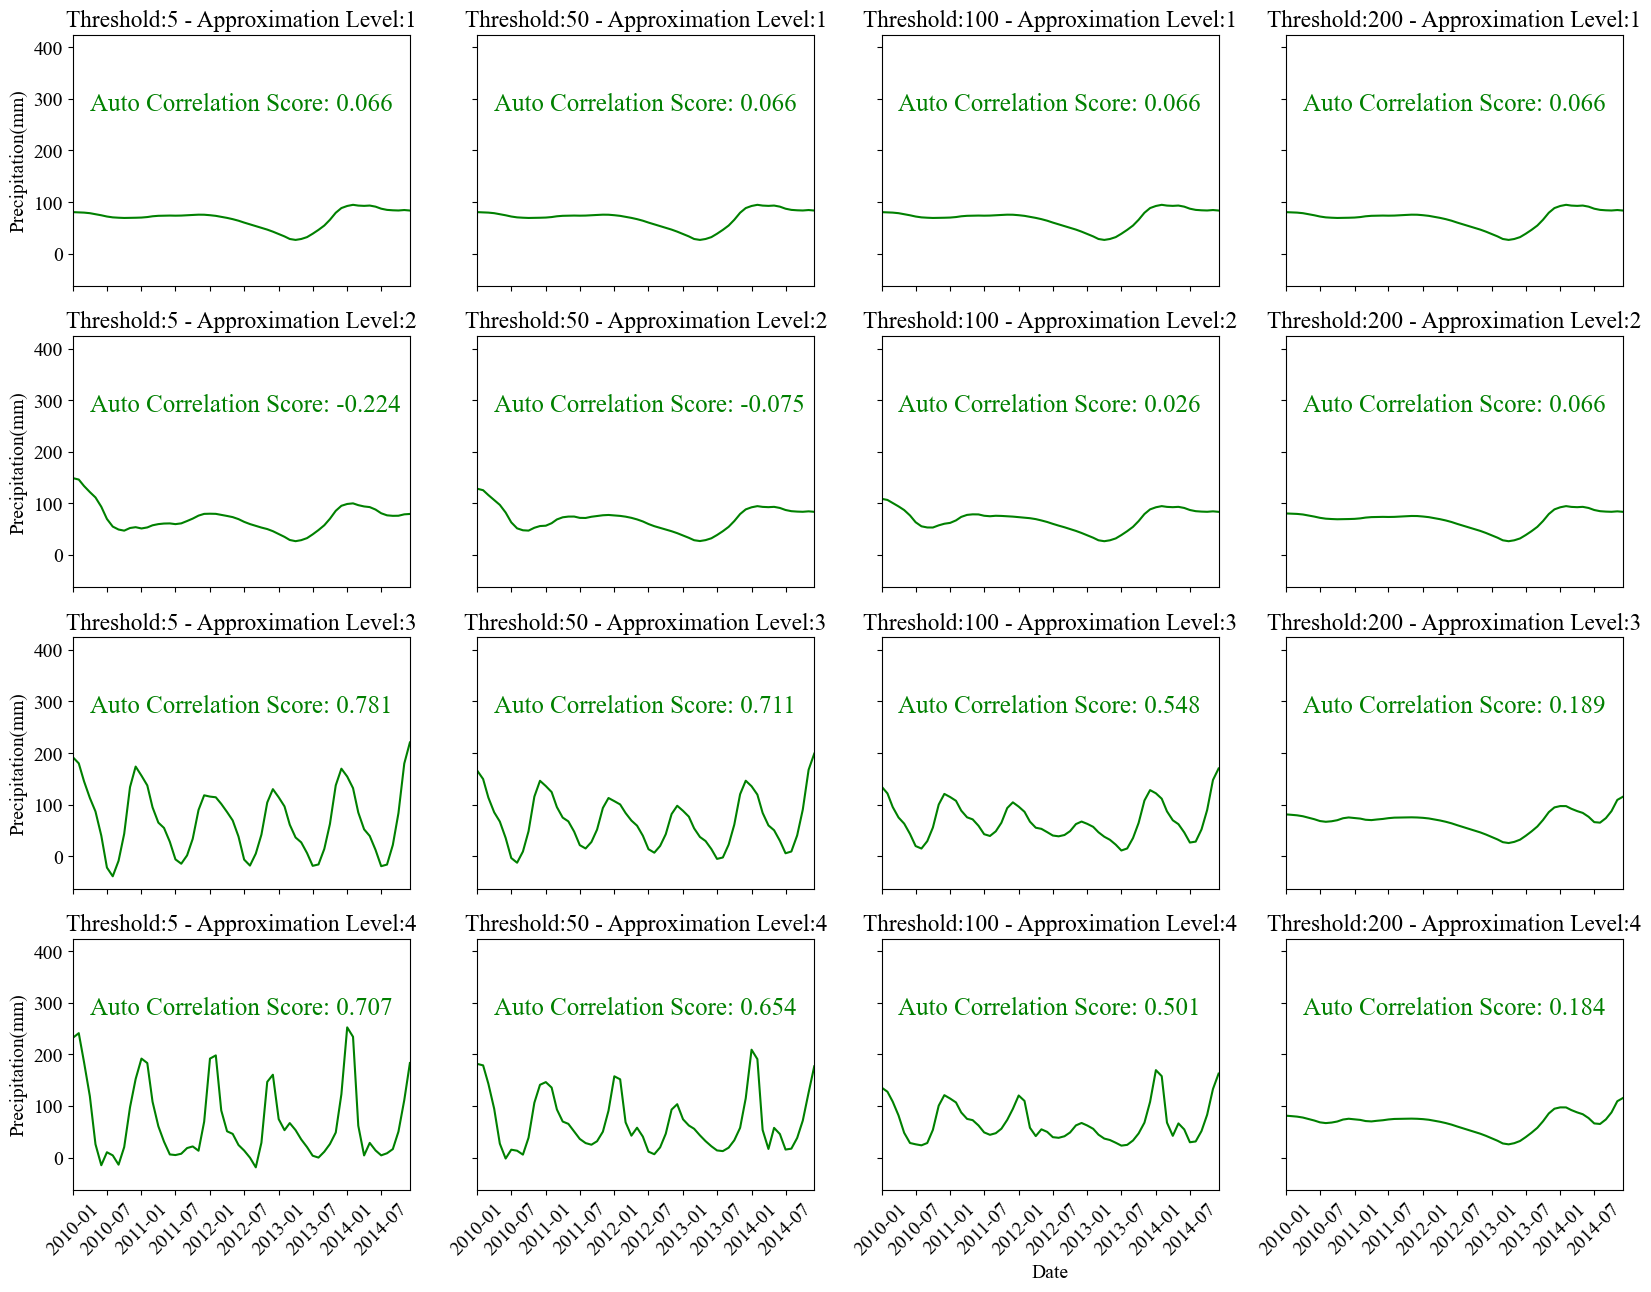

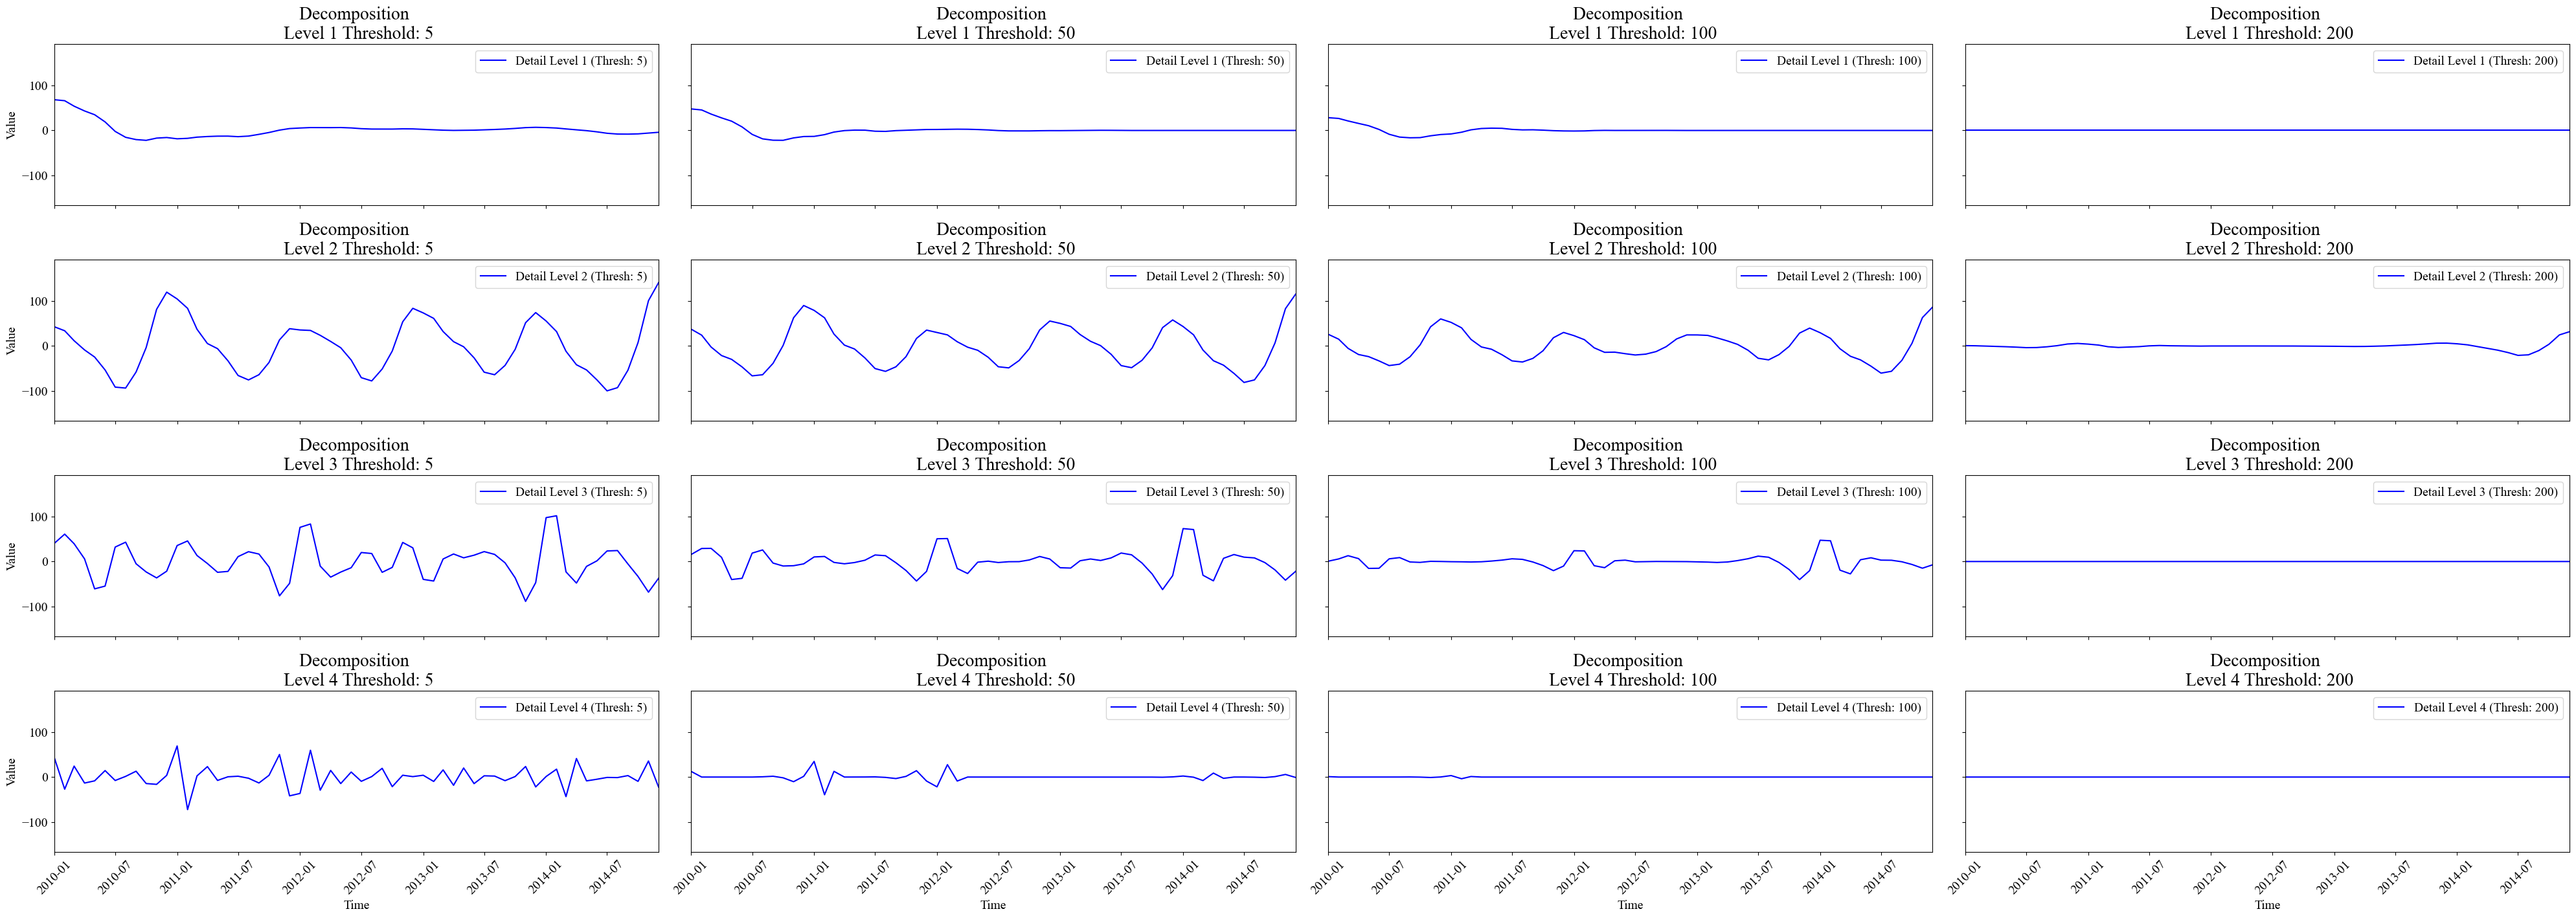

{'approx': ['r7i1p1f1,gr1_approx']}


In [64]:
thresholds = [5,50, 100,200]
wavelet = 'db4'
level = 4
selected_level = 3
smoothed_inputs = {}

for variant in selected_variants:
    grid = selected_columns[variant][0]  # Select the first grid
    fig, axes = plt.subplots(nrows=level, ncols=len(thresholds), figsize=(20, 15), sharex=True, sharey=True)
    #fig.suptitle(f'Wavelet Denoising Approximations for {grid} at Different Thresholds and Levels', fontsize=16)
    fig_dec, axes_dec = plt.subplots(nrows=level, ncols=len(thresholds), figsize=(40, 15), sharex=True, sharey=True)
    #fig_dec.suptitle(f'Wavelet Denoising Decompositions for {grid} at Different Levels', fontsize=16)
    
    for col, threshold in enumerate(thresholds):
        coeffs = pywt.wavedec(gcms[grid], wavelet, level=level, mode='periodization')
        thresholded_coeffs = [coeffs[0]] + [pywt.threshold(c, threshold, mode='soft') for c in coeffs[1:]]
        
        approximations = []
        decompositions = []
        for i in range(level):
            coeffs_copy = thresholded_coeffs.copy()
            coeffs_copy[i+1:] = [np.zeros_like(c) for c in coeffs[i+1:]]
            approximations.append(pywt.waverec(coeffs_copy, wavelet, mode='periodization')[:len(observations.values)])
            coeffs_copy = [np.zeros_like(c) for c in coeffs]
            coeffs_copy[i+1] = thresholded_coeffs[i+1]  # Keep only the detail at level i
            decompositions.append(pywt.waverec(coeffs_copy, wavelet, mode='periodization')[:len(observations.values)])
        
        for row, approx in enumerate(approximations):
            if row + 1 == selected_level:
                gcms[f'{grid}_approx'] = approx
            axes[row, col].plot(time, approx,  color='green')
            ac_score = pd.Series(approx).autocorr(lag=12)
            axes[row, col].text(x=0.05, y=0.7, s=f'Auto Correlation Score: {round(ac_score, 3)}', fontdict={'size': 18, 'color': 'green', 'font': 'Times New Roman'}, transform=axes[row, col].transAxes)
            axes[row, col].title.set_text(f'Threshold:{threshold} - Approximation Level:{row+1}')
            axes[row, col].set_xlim(pd.Timestamp('2010-01-01'), pd.Timestamp('2014-12-01'))   

            if row == 3 :
                axes[row, col].tick_params(axis='x', rotation=45)   
            if col == 0:
                axes[row, col].set_ylabel('Precipitation(mm)')
            if row == 3 and col == 2:
                axes[row, col].set_xlabel('Date')
                
        for row, decomp in enumerate(decompositions):
            if row + 1 == selected_level:
                gcms[f'{grid}_decomp'] = decomp
            axes_dec[row, col].plot(time, decomp, label=f'Detail Level {row+1} (Thresh: {threshold})', color='blue')
            axes_dec[row, col].set_title(f'Decomposition \n Level {row+1} Threshold: {threshold}', fontdict={'family': 'Times New Roman', 'size': 20})
            axes_dec[row, col].legend()
            axes_dec[row, col].set_xlim(pd.Timestamp('2010-01-01'), pd.Timestamp('2014-12-01'))
           
            if row == 3:
                axes_dec[row, col].set_xlabel('Time')
                axes_dec[row, col].tick_params(axis='x', rotation=45)  
            if col == 0:
                axes_dec[row, col].set_ylabel('Value')
    
    plt.rcParams['font.family'] = 'Times New Roman'
    plt.rcParams['font.size'] = 14
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
    smoothed_inputs = {v: [c for c in gcms.columns if v in c] for v in ['approx']}
    print(smoothed_inputs)
